# Thí nghiệm so sánh RNN và LSTM (PyTorch)
**Nhóm 5:** Nguyễn Phú Đại · Trần Vũ Tiến Minh · Trần Đình Hiếu · Phạm Thanh An

Notebook này sinh toàn bộ số liệu cho 2 slide thí nghiệm của bài thuyết trình LSTM:

| Phần | Bài toán | Slide | File kết quả |
|---|---|---|---|
| 1 | **Adding Problem** (dữ liệu tổng hợp, có phụ thuộc xa) | Thí nghiệm 2 | `slides/data/compare.json` |
| 2 | **E-commerce (Olist)**: dự báo số đơn hàng mỗi ngày | Thí nghiệm 1 | `slides/data/ecommerce.json` |

Ở cả hai phần, RNN và LSTM dùng cùng kiến trúc `RNN/LSTM(hidden 64) → h_T → Linear(1)`, cùng optimizer, cùng dữ liệu; chỉ khác lớp hồi quy (`nn.RNN` hay `nn.LSTM`).

In [1]:
import copy, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(4)
SLIDES_DATA = Path('..') / 'slides' / 'data'      # notebook nằm trong thư mục experiment/
SLIDES_DATA.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 100
print('PyTorch', torch.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)

PyTorch 2.14.0+cpu | numpy 2.5.3 | pandas 3.0.6


# Phần 1 — Adding Problem

Mỗi mẫu là chuỗi độ dài $T$, mỗi bước gồm 2 giá trị: một số ngẫu nhiên $\sim U(0, 1)$ và một cờ 0/1. Đúng 2 vị trí có cờ 1: một ở nửa đầu, một ở nửa sau chuỗi. Mục tiêu là **tổng 2 số tại 2 vị trí đó**. Vì vị trí thứ nhất nằm ở nửa đầu, mô hình phải giữ giá trị đó qua ít nhất $T/2$ bước.

**Mô hình cơ sở:** luôn dự đoán hằng số 1 (kỳ vọng của tổng) → MSE = phương sai của tổng = $2 \cdot \frac{1}{12} = \frac{1}{6} \approx 0.167$.

**Cấu hình chung:** hidden 64, Adam lr 1e-3, batch 64, 5000 bước (mỗi bước sinh một batch mới), clip gradient 1.0. So sánh $T = 10$ (phụ thuộc ngắn) và $T = 100$ (phụ thuộc xa).

In [2]:
HIDDEN, BATCH, STEPS, LR, LOG_EVERY = 64, 64, 5000, 1e-3, 25
SEQ_LENS = [10, 100]

def make_batch(batch, T, gen):
    values = torch.rand(batch, T, generator=gen)
    marks = torch.zeros(batch, T)
    first = torch.randint(0, T // 2, (batch,), generator=gen)
    second = torch.randint(T // 2, T, (batch,), generator=gen)
    idx = torch.arange(batch)
    marks[idx, first] = 1.0
    marks[idx, second] = 1.0
    x = torch.stack([values, marks], dim=-1)          # (batch, T, 2)
    y = (values * marks).sum(dim=1, keepdim=True)      # (batch, 1)
    return x, y

x, y = make_batch(1, 10, torch.Generator().manual_seed(0))
print('Ví dụ một mẫu T = 10 (cột 1: giá trị, cột 2: cờ):')
print(x[0].numpy().round(3))
print('Mục tiêu y =', y.item().__round__(3))

Ví dụ một mẫu T = 10 (cột 1: giá trị, cột 2: cờ):
[[0.496 0.   ]
 [0.768 1.   ]
 [0.088 0.   ]
 [0.132 0.   ]
 [0.307 0.   ]
 [0.634 0.   ]
 [0.49  1.   ]
 [0.896 0.   ]
 [0.456 0.   ]
 [0.632 0.   ]]
Mục tiêu y = 1.258


In [3]:
class SeqModel(nn.Module):
    def __init__(self, cell, input_size=2, hidden=HIDDEN):
        super().__init__()
        rnn_cls = nn.LSTM if cell == 'lstm' else nn.RNN
        self.rnn = rnn_cls(input_size=input_size, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.fc(output[:, -1])                  # many-to-one: lấy bước cuối


def train_adding(cell, T, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = SeqModel(cell)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    curve, window = [], []
    start = time.time()
    for step in range(1, STEPS + 1):
        x, y = make_batch(BATCH, T, gen)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        window.append(loss.item())
        if step % LOG_EVERY == 0:
            curve.append([step, sum(window) / len(window)])
            window = []
    elapsed = time.time() - start
    model.eval()
    with torch.no_grad():                              # tập test cố định: 2000 mẫu
        x, y = make_batch(2000, T, torch.Generator().manual_seed(12345))
        test_mse = loss_fn(model(x), y).item()
    params = sum(p.numel() for p in model.parameters())
    print(f'{cell:4s} T={T:3d}  test MSE={test_mse:.4f}  params={params}  time={elapsed:.0f}s')
    return {'curve': curve, 'test_mse': test_mse, 'params': params, 'seconds': round(elapsed, 1)}

In [4]:
adding = {'config': {'hidden': HIDDEN, 'batch': BATCH, 'steps': STEPS, 'lr': LR,
                     'optimizer': 'Adam', 'clip': 1.0, 'baseline_mse': 1 / 6},
          'runs': {}}
for T in SEQ_LENS:
    adding['runs'][str(T)] = {cell: train_adding(cell, T) for cell in ('rnn', 'lstm')}

(SLIDES_DATA / 'compare.json').write_text(json.dumps(adding, indent=1), encoding='utf-8')
print('Đã lưu', SLIDES_DATA / 'compare.json')

rnn  T= 10  test MSE=0.0012  params=4417  time=4s


lstm T= 10  test MSE=0.0001  params=17473  time=5s


rnn  T=100  test MSE=0.1628  params=4417  time=24s


lstm T=100  test MSE=0.0033  params=17473  time=31s
Đã lưu ../slides/data/compare.json


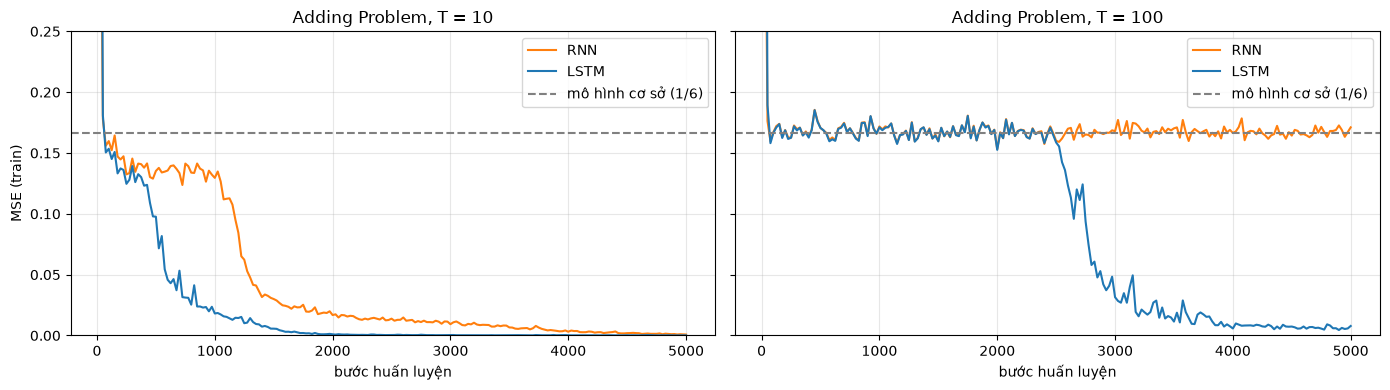

,T,mô hình,test MSE,tham số,thời gian (s)
0,10,RNN,0.0012,4417,4.5
1,10,LSTM,0.0001,17473,5.0
2,100,RNN,0.1628,4417,24.3
3,100,LSTM,0.0033,17473,30.8


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, T in zip(axes, SEQ_LENS):
    for cell, color in (('rnn', 'tab:orange'), ('lstm', 'tab:blue')):
        c = np.array(adding['runs'][str(T)][cell]['curve'])
        ax.plot(c[:, 0], c[:, 1], color=color, label=cell.upper())
    ax.axhline(1 / 6, color='grey', ls='--', label='mô hình cơ sở (1/6)')
    ax.set_title(f'Adding Problem, T = {T}'); ax.set_xlabel('bước huấn luyện'); ax.set_ylim(0, 0.25)
    ax.legend(); ax.grid(alpha=.3)
axes[0].set_ylabel('MSE (train)')
plt.tight_layout(); plt.show()

pd.DataFrame([{'T': T, 'mô hình': cell.upper(), 'test MSE': r['test_mse'], 'tham số': r['params'], 'thời gian (s)': r['seconds']}
              for T, d in adding['runs'].items() for cell, r in d.items()]).round(4)

**Nhận xét (Phần 1)**
* $T = 10$: cả hai mô hình đều học được (loss giảm xa dưới mức cơ sở 0.167).
* $T = 100$: loss của RNN nằm ở mức cơ sở suốt quá trình huấn luyện → RNN không học được phụ thuộc cách ≥ 50 bước. LSTM sau một giai đoạn đầu cũng nằm ở mức cơ sở, rồi giảm mạnh xuống gần 0.
* Giải thích: gradient của RNN qua $k$ bước là tích $\prod \operatorname{diag}(\tanh')\,W_h$ nên biến mất; ở LSTM, đường trực tiếp qua cell state chỉ nhân với $f_t$, mạng học giữ $f_t \approx 1$ nên gradient vẫn truyền về được.
* Chi phí: LSTM có gần gấp 4 tham số và huấn luyện lâu hơn.

# Phần 2 — Dữ liệu e-commerce (Olist): dự báo số đơn hàng mỗi ngày

Tiền xử lý, kiến trúc và siêu tham số giống hệt các notebook RNN trong `rnn codes/` (`01_RNN_Scratch`, `02_RNN_Keras`, `03_RNN_PyTorch`):
* Chuỗi số đơn hàng được đặt mỗi ngày, 15/01/2017 → 22/08/2018 (585 ngày).
* Cửa sổ trượt 14 ngày → dự báo ngày kế tiếp (*many-to-one*).
* Chia 80/20 **theo thời gian**; chuẩn hóa Min-Max bằng thống kê của tập train; 10% cuối tập train làm validation.
* Hidden 64, batch 32, clip 1.0, early stopping theo validation loss (giữ trọng số tốt nhất).

Mô hình LSTM chỉ thay `nn.RNN` bằng `nn.LSTM`. Mỗi cấu hình chạy 5 seed để thấy độ dao động.

(99441, 8) | số ngày: 585


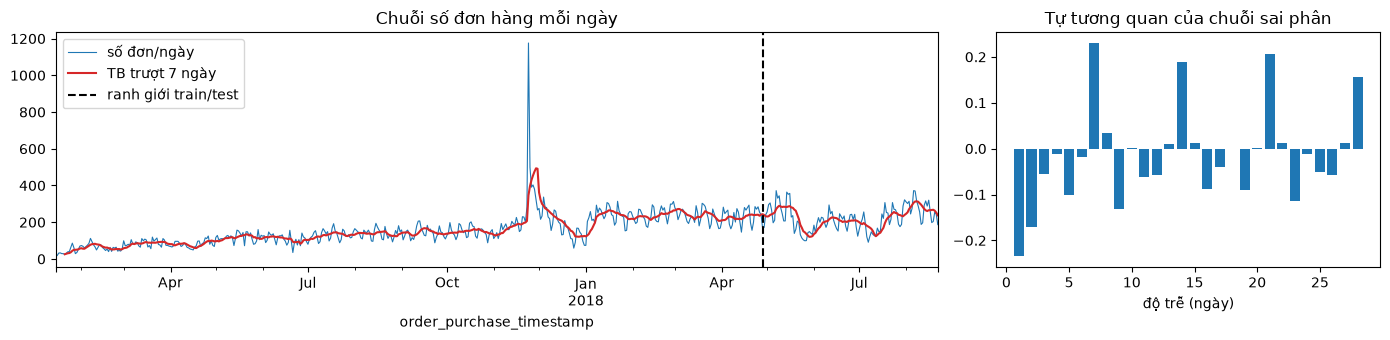

In [6]:
CSV = Path('olist_orders_dataset.csv')
if not CSV.exists():   # tải từ repo công khai của Olist nếu chưa có file
    import urllib.request
    urllib.request.urlretrieve('https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/olist_orders_dataset.csv', CSV)

orders = pd.read_csv(CSV, parse_dates=['order_purchase_timestamp'])
series = orders.set_index('order_purchase_timestamp').resample('D').size().astype(float)['2017-01-15':'2018-08-22']
print(orders.shape, '| số ngày:', len(series))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2.3, 1]})
series.plot(ax=ax[0], lw=.8, label='số đơn/ngày'); series.rolling(7).mean().plot(ax=ax[0], color='tab:red', label='TB trượt 7 ngày')
ax[0].axvline(series.index[int(len(series) * .8)], color='k', ls='--', label='ranh giới train/test'); ax[0].legend(); ax[0].set_title('Chuỗi số đơn hàng mỗi ngày')
lags = range(1, 29)
ax[1].bar(lags, [series.diff().autocorr(l) for l in lags]); ax[1].set_title('Tự tương quan của chuỗi sai phân'); ax[1].set_xlabel('độ trễ (ngày)')
plt.tight_layout(); plt.show()

Tự tương quan của chuỗi sai phân có đỉnh tại các độ trễ 7, 14, 21, 28: cấu trúc chính của chuỗi là **chu kỳ tuần** và mức đơn hàng gần nhất — đều là thông tin nằm trong 1–2 tuần gần nhất.

In [7]:
def prepare(series, window, train_ratio=0.8):
    values = series.values.astype(np.float64)
    n_train = int(len(values) * train_ratio)
    target_idx = np.arange(window, len(values))
    windows = np.stack([values[i - window:i] for i in target_idx])
    targets = values[target_idx]
    is_train = target_idx < n_train
    lo, hi = values[:n_train].min(), values[:n_train].max()           # Min-Max fit trên train
    X, y = (windows - lo) / (hi - lo), (targets - lo) / (hi - lo)
    return dict(X_train=X[is_train][..., None], y_train=y[is_train][:, None],
                X_test=X[~is_train][..., None], y_test_orig=targets[~is_train],
                naive_test=values[target_idx - 1][~is_train],            # baseline: giá trị hôm trước
                dates_test=series.index[target_idx[~is_train]],
                inverse=lambda v: np.ravel(v) * (hi - lo) + lo)


def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    err = y_pred - y_true
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))), MAE=float(np.mean(np.abs(err))),
                MAPE=float(np.mean(np.abs(err / y_true)) * 100),
                R2=float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)))


d14 = prepare(series, 14)
print('X_train', d14['X_train'].shape, '| X_test', d14['X_test'].shape)
print('Naive (x_t = x_{t-1}):', {k: round(v, 3) for k, v in regression_metrics(d14['y_test_orig'], d14['naive_test']).items()})

X_train (454, 14, 1) | X_test (117, 14, 1)
Naive (x_t = x_{t-1}): {'RMSE': 49.345, 'MAE': 37.684, 'MAPE': 17.589, 'R2': 0.466}


In [8]:
class Regressor(nn.Module):
    def __init__(self, cell, hidden=64):
        super().__init__()
        self.rnn = (nn.LSTM if cell == 'lstm' else nn.RNN)(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
        if cell == 'rnn':   # giống notebook 03: W_hh trực giao, bias = 0
            for name, p in self.rnn.named_parameters():
                if 'weight_hh' in name: nn.init.orthogonal_(p)
                elif 'bias' in name:    nn.init.zeros_(p)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def train_ecom(d, cell, seed, lr, epochs, patience, batch=32, clip=1.0):
    torch.manual_seed(seed)
    X = torch.tensor(d['X_train'], dtype=torch.float32)
    y = torch.tensor(d['y_train'], dtype=torch.float32)
    n_val = int(len(X) * 0.1)
    dl = DataLoader(TensorDataset(X[:-n_val], y[:-n_val]), batch_size=batch, shuffle=True)
    X_val, y_val = X[-n_val:], y[-n_val:]
    model = Regressor(cell)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    hist, best, best_state, wait = [], float('inf'), None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in dl:
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_val), y_val).item()
        hist.append(val)
        if val < best:
            best, best_state, wait = val, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = d['inverse'](model(torch.tensor(d['X_test'], dtype=torch.float32)).numpy())
    return dict(pred=pred, epochs=len(hist), best_val=best, val_curve=hist, seconds=round(time.time() - t0, 1),
                params=sum(p.numel() for p in model.parameters()), **regression_metrics(d['y_test_orig'], pred))


SEEDS = [42, 0, 1, 2, 3]
r = train_ecom(d14, 'rnn', seed=42, lr=1e-3, epochs=150, patience=15)
print(f"Kiểm tra: nn.RNN, seed 42, cấu hình notebook 03 → RMSE = {r['RMSE']:.3f} (notebook 03: 40.123), {r['epochs']} epoch")

Kiểm tra: nn.RNN, seed 42, cấu hình notebook 03 → RMSE = 40.123 (notebook 03: 40.123), 88 epoch


## 2.1 Dò siêu tham số (chọn theo validation, không nhìn tập test)

Với đúng cấu hình của notebook 03 (lr 1e-3, tối đa 150 epoch, patience 15), LSTM có thể chưa hội tụ. Để so sánh công bằng, ta dò cùng một lưới cho **cả hai** mô hình: lr ∈ {1e-3, 3e-3, 1e-2} × (patience 15 / tối đa 150 epoch, hoặc patience 50 / tối đa 500 epoch), cửa sổ 14 ngày. Ngoài ra thử các cửa sổ dài hơn (28, 56, 112 ngày) để xem LSTM có tận dụng được ngữ cảnh dài hay không.

In [9]:
GRID = [(14, lr, pat, ep) for lr in (1e-3, 3e-3, 1e-2) for pat, ep in ((15, 150), (50, 500))]
GRID += [(w, lr, 50, 500) for w in (28, 56, 112) for lr in (3e-3, 1e-2)]

sweep, rows = {}, []
for w, lr, pat, ep in GRID:
    d = d14 if w == 14 else prepare(series, w)
    for cell in ('rnn', 'lstm'):
        runs = [train_ecom(d, cell, s, lr, ep, pat) for s in SEEDS]
        sweep[(w, cell, lr, pat)] = runs
        rows.append({'window': w, 'cell': cell, 'lr': lr, 'patience': pat, 'max_epochs': ep,
                     'val_loss': np.mean([x['best_val'] for x in runs]),
                     'RMSE_mean': np.mean([x['RMSE'] for x in runs]), 'RMSE_std': np.std([x['RMSE'] for x in runs]),
                     'epochs_mean': np.mean([x['epochs'] for x in runs])})
sweep_df = pd.DataFrame(rows)
sweep_df.round({'val_loss': 5, 'RMSE_mean': 2, 'RMSE_std': 2, 'epochs_mean': 0})

,window,cell,lr,patience,max_epochs,val_loss,RMSE_mean,RMSE_std,epochs_mean
0,14,rnn,0.001,15,150,0.00083,40.75,1.11,87.0
1,14,lstm,0.001,15,150,0.00145,51.80,4.42,101.0
2,14,rnn,0.001,50,500,0.00076,39.30,0.62,172.0
3,14,lstm,0.001,50,500,0.00084,43.65,3.93,417.0
4,14,rnn,0.003,15,150,0.00087,41.30,2.21,53.0
5,14,lstm,0.003,15,150,0.00086,39.98,1.00,133.0
6,14,rnn,0.003,50,500,0.00075,39.57,0.88,151.0
7,14,lstm,0.003,50,500,0.00080,40.78,3.11,221.0
8,14,rnn,0.010,15,150,0.00092,45.37,9.86,42.0
9,14,lstm,0.010,15,150,0.00085,40.44,1.06,96.0


In [10]:
w14 = sweep_df[sweep_df.window == 14]
best = w14.loc[w14.groupby('cell').val_loss.idxmin()]
print('Cấu hình có val loss thấp nhất (cửa sổ 14 ngày):')
best[['cell', 'lr', 'patience', 'max_epochs', 'val_loss', 'RMSE_mean', 'RMSE_std']].round(5)

Cấu hình có val loss thấp nhất (cửa sổ 14 ngày):


,cell,lr,patience,max_epochs,val_loss,RMSE_mean,RMSE_std
7,lstm,0.003,50,500,0.00080,40.77666,3.11038
6,rnn,0.003,50,500,0.00075,39.56839,0.87781


Cả hai mô hình cùng chọn **lr = 3e-3, patience 50, tối đa 500 epoch**. Ta gọi:
* **Cấu hình A** — giống notebook 03: lr 1e-3, tối đa 150 epoch, patience 15.
* **Cấu hình B** — cấu hình có val loss thấp nhất: lr 3e-3, tối đa 500 epoch, patience 50.

In [11]:
CONFIGS = {'A': dict(lr=1e-3, epochs=150, patience=15), 'B': dict(lr=3e-3, epochs=500, patience=50)}
keys = ['RMSE', 'MAE', 'MAPE', 'R2']
summary = {}
for cname, cfg in CONFIGS.items():
    for cell in ('rnn', 'lstm'):
        runs = sweep[(14, cell, cfg['lr'], cfg['patience'])]
        summary[f'{cname}_{cell}'] = {
            'params': runs[0]['params'],
            'mean': {k: float(np.mean([x[k] for x in runs])) for k in keys},
            'std': {k: float(np.std([x[k] for x in runs])) for k in keys},
            'epochs_mean': float(np.mean([x['epochs'] for x in runs])),
            'seed42': {k: runs[0][k] for k in keys + ['epochs', 'seconds']},
            'pred_seed42': [round(float(v), 1) for v in runs[0]['pred']]}

naive = regression_metrics(d14['y_test_orig'], d14['naive_test'])
table = [{'Mô hình': 'Naive (x_t = x_{t-1})', 'Huấn luyện': '—', 'Tham số': 0, **{k: naive[k] for k in keys}},
         # 3 dòng RNN lấy từ output của các notebook trong rnn codes/ (1 lần chạy, seed 42)
         {'Mô hình': 'RNN · NumPy (01_RNN_Scratch)', 'Huấn luyện': 'A · 1 lần', 'Tham số': 4289, 'RMSE': 42.511, 'MAE': 34.421, 'MAPE': 17.487, 'R2': 0.604},
         {'Mô hình': 'RNN · Keras SimpleRNN (02_RNN_Keras)', 'Huấn luyện': 'A · 1 lần', 'Tham số': 4289, 'RMSE': 41.297, 'MAE': 32.743, 'MAPE': 16.139, 'R2': 0.626},
         {'Mô hình': 'RNN · PyTorch (03_RNN_PyTorch)', 'Huấn luyện': 'A · 1 lần', 'Tham số': 4353, 'RMSE': 40.123, 'MAE': 31.465, 'MAPE': 15.398, 'R2': 0.647}]
for name, s in summary.items():
    cname, cell = name.split('_')
    table.append({'Mô hình': f"{'LSTM' if cell == 'lstm' else 'RNN'} · PyTorch (notebook này)", 'Huấn luyện': f'{cname} · TB 5 seed',
                  'Tham số': s['params'], **s['mean'], 'RMSE ± std': f"{s['mean']['RMSE']:.1f} ± {s['std']['RMSE']:.1f}",
                  'epoch TB': round(s['epochs_mean'])})
pd.DataFrame(table).round(3)

,Mô hình,Huấn luyện,Tham số,RMSE,MAE,MAPE,R2,RMSE ± std,epoch TB
0,Naive (x_t = x_{t-1}),—,0,49.345,37.684,17.589,0.466,NaN,NaN
1,RNN · NumPy (01_RNN_Scratch),A · 1 lần,4289,42.511,34.421,17.487,0.604,NaN,NaN
2,RNN · Keras SimpleRNN (02_RNN_Keras),A · 1 lần,4289,41.297,32.743,16.139,0.626,NaN,NaN
3,RNN · PyTorch (03_RNN_PyTorch),A · 1 lần,4353,40.123,31.465,15.398,0.647,NaN,NaN
4,RNN · PyTorch (notebook này),A · TB 5 seed,4353,40.751,32.399,16.306,0.636,40.8 ± 1.1,87.0
5,LSTM · PyTorch (notebook này),A · TB 5 seed,17217,51.801,42.261,21.446,0.408,51.8 ± 4.4,101.0
6,RNN · PyTorch (notebook này),B · TB 5 seed,4353,39.568,31.157,15.443,0.657,39.6 ± 0.9,151.0
7,LSTM · PyTorch (notebook này),B · TB 5 seed,17217,40.777,32.288,15.302,0.633,40.8 ± 3.1,221.0


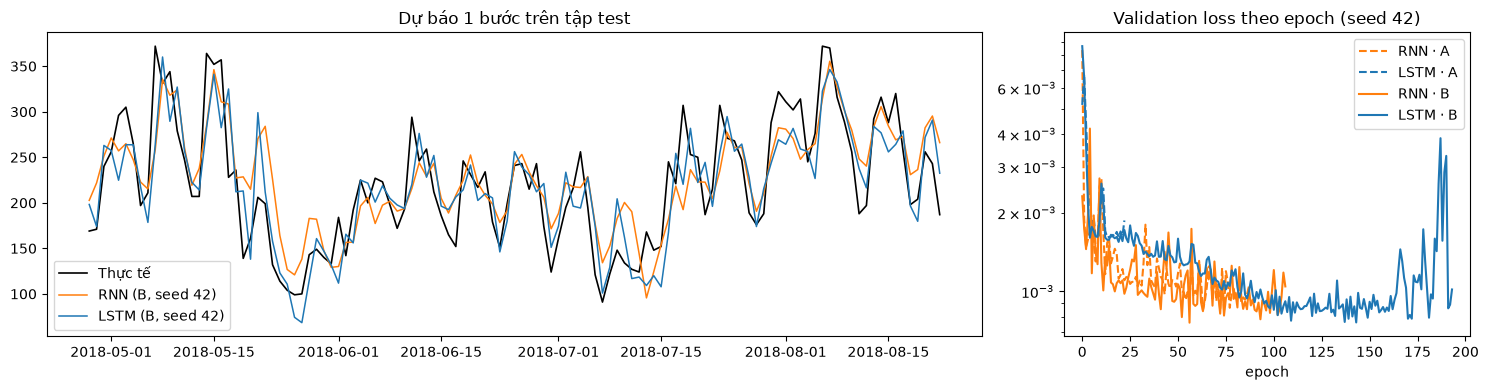

In [12]:
dates = d14['dates_test']
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [2.3, 1]})
axes[0].plot(dates, d14['y_test_orig'], color='black', lw=1.2, label='Thực tế')
axes[0].plot(dates, summary['B_rnn']['pred_seed42'], color='tab:orange', lw=1.1, label='RNN (B, seed 42)')
axes[0].plot(dates, summary['B_lstm']['pred_seed42'], color='tab:blue', lw=1.1, label='LSTM (B, seed 42)')
axes[0].set_title('Dự báo 1 bước trên tập test'); axes[0].legend()
for cfg, ls in (('A', '--'), ('B', '-')):
    for cell, color in (('rnn', 'tab:orange'), ('lstm', 'tab:blue')):
        c = sweep[(14, cell, CONFIGS[cfg]['lr'], CONFIGS[cfg]['patience'])][0]['val_curve']
        axes[1].plot(c, ls=ls, color=color, label=f'{cell.upper()} · {cfg}')
axes[1].set_yscale('log'); axes[1].set_title('Validation loss theo epoch (seed 42)'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

In [13]:
ecom = {'config': dict(window=14, hidden=64, batch=32, clip=1.0, seeds=SEEDS, series_len=len(series),
                       n_train=len(d14['X_train']), n_test=len(d14['X_test']), configs=CONFIGS),
        'naive': naive, 'dates_test': [str(t.date()) for t in dates], 'y_test': d14['y_test_orig'].tolist(),
        'runs': summary,
        'sweep': sweep_df.to_dict(orient='records')}
(SLIDES_DATA / 'ecommerce.json').write_text(json.dumps(ecom, ensure_ascii=False, indent=1), encoding='utf-8')
print('Đã lưu', SLIDES_DATA / 'ecommerce.json')

Đã lưu ../slides/data/ecommerce.json


**Nhận xét (Phần 2)**
* Ba bản RNN (NumPy, Keras, PyTorch) đều tốt hơn baseline naive (RMSE ≈ 40–42 so với 49.3).
* **Cấu hình A** (siêu tham số của notebook RNN): LSTM kém hơn RNN, thậm chí kém baseline. LSTM hội tụ chậm hơn: có seed dừng sớm, có seed chạy hết 150 epoch mà chưa hội tụ.
* **Cấu hình B** (chọn theo validation cho cả hai mô hình): RNN và LSTM tương đương; chênh lệch nằm trong độ dao động giữa các seed. Cửa sổ dài hơn (28, 56, 112 ngày) cũng không tạo ra khác biệt rõ.
* Ở lr 1e-2, RMSE của RNN dao động mạnh giữa các seed, còn LSTM ổn định hơn.
* **Vì sao LSTM không tốt hơn ở đây:** thông tin dự báo nằm trong 1–2 tuần gần nhất (mức đơn hàng, chu kỳ tuần), không có phụ thuộc xa để cơ chế cell state phát huy; dữ liệu nhỏ (≈ 410 mẫu train) trong khi LSTM có gấp 4 tham số.

# Kết luận
LSTM tốt hơn RNN rõ rệt khi bài toán có **phụ thuộc xa** (Adding Problem, $T = 100$), vì gradient truyền qua cell state không bị nhân lặp với $W_h$ và $\tanh'$. Khi phụ thuộc ngắn và dữ liệu ít (chuỗi đơn hàng Olist với cửa sổ 14 ngày), RNN cơ bản là đủ; LSTM chỉ tốn thêm tham số và thời gian huấn luyện.